### Neural network, experimentation tool, version 2, scaled version

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# activation functions
# ReLu is very simple, it filters out all negative values
# this is a powerful activation function in reality
def activation_ReLu(number):
    if number > 0:
        return number
    else:
        return 0

# we also need a derivated version of ReLu
# otherwise same as original, but instead of origina value, return 1 instead
def activation_ReLu_derivative(number):
    if number > 0:
        return 1
    else:
        return 0

In [12]:
# lock down the randomness in order to get same results everytime
# you can change or disable this if you want
np.random.seed(2026)

def generate_training_data():
    result = []

    # create 100 numbers
    for x in range(100):
        n1 = np.random.randint(0, 5)
        n2 = np.random.randint(3, 7)
        n3 = n1 ** 2 + n2 + np.random.randint(0, 5)

        result.append([n1, n2, n3])

    return result

In [13]:
# initialize weights and biases
# in Keras/TensorFlow/PyTorch etc. these are usually randomized in the beginning
w1 = 1.5
w2 = 0.5
w3 = -2
w4 = -0.5
w5 = 1.5
w6 = 1.2
bias1 = 0.5
bias2 = -0.35
bias3 = 0.5

# just for comparison after the training
original_w1 = w1
original_w2 = w2
original_w3 = w3
original_w4 = w4
original_w5 = w5
original_w6 = w6
original_b1 = bias1
original_b2 = bias2
original_b3 = bias3

# our training data
# x1 = input1, x2 = input2, y = true_value

# use generated training data from our helper function
data = generate_training_data()

df = pd.DataFrame(data, columns=['x1', 'x2', 'y'])

# DataFrame values as a list
data = list(df.values)

# use min/max -scaling to make values in the range 0-1
# NOTE: change this => scale X-values and y -values separately
data = (data - np.min(data)) / (np.max(data) - np.min(data))

# learning rate
LR = 0.025
epochs = 1000

# let's initialize a list for loss visualizations
loss_points = []

# training loop
for epoch in range(epochs):

    # the previous version only measured the loss value
    # of the last calculation done in the code (node 3)
    # it's probably better to measure the average loss for each epoch
    epoch_losses = []

    for row in data:
        # this is where we do Forward pass + backpropagation
        input1 = row[0]
        input2 = row[1]
        true_value = row[2]

        # NODE 1 OUTPUT
        node_1_output = input1 * w1 + input2 * w3 + bias1
        node_1_output = activation_ReLu(node_1_output)

        # NODE 2 OUTPUT
        node_2_output = input1 * w2 + input2 * w4 + bias2
        node_2_output = activation_ReLu(node_2_output)

        # NODE 3 OUTPUT
        # we can just use Node 1 and 2 outputs, since they already
        # contain the previous weights in their result
        node_3_output = node_1_output * w5 + node_2_output * w6 + bias3
        node_3_output = activation_ReLu(node_3_output)

        # LOSS FUNCTION - we are going to use MSE -> mean squared error
        # MSE formula for LOSS => (predicted_value - true_value)^2
        predicted_value = node_3_output
        loss = (predicted_value - true_value) ** 2

        # add current loss into epoch losses -list
        epoch_losses.append(loss)

        # BACKPROPAGATION - LAST LAYER FIRST
        # solving the partial derivative of the loss function with respect to w5
        deriv_L_w5 = 2 * node_1_output * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_w5 = w5 - LR * deriv_L_w5

        deriv_L_w6 = 2 * node_2_output * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_w6 = w6 - LR * deriv_L_w6

        deriv_L_b3 = 2 * 1 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_b3 = bias3 - LR * deriv_L_b3

        # BACKPROPAGATION - THE FIRST LAYER
        # FROM THIS POINT ONWARD WE HAVE TO USE THE MORE COMPLEX
        # VERSION OF UPDATING THE VALUES => CHAIN RULE

        # weight 1
        deriv_L_w1_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w1_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * input1
        deriv_L_w1 = deriv_L_w1_left * deriv_L_w1_right
        new_w1 = w1 - LR * deriv_L_w1

        # weight 2
        deriv_L_w2_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w2_right = activation_ReLu_derivative(input1 * w2 + input2 * w4 + bias2) * input1
        deriv_L_w2 = deriv_L_w2_left * deriv_L_w2_right
        new_w2 = w2 - LR * deriv_L_w2

        # weight 3
        deriv_L_w3_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w3_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * input2
        deriv_L_w3 = deriv_L_w3_left * deriv_L_w3_right
        new_w3 = w3 - LR * deriv_L_w3

        # weight 4
        deriv_L_w4_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w4_right = activation_ReLu_derivative(input1 * w2 + input2 * w4 + bias2) * input2
        deriv_L_w4 = deriv_L_w4_left * deriv_L_w4_right
        new_w4 = w4 - LR * deriv_L_w4

        # bias 1
        deriv_L_b1_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_b1_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * 1
        deriv_L_b1 = deriv_L_b1_left * deriv_L_b1_right
        new_b1 = bias1 - LR * deriv_L_b1

        # bias 2
        deriv_L_b2_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_b2_right = activation_ReLu_derivative(input1 * w2 + input2 * w3 + bias2) * 1
        deriv_L_b2 = deriv_L_b2_left * deriv_L_b2_right
        new_b2 = bias2 - LR * deriv_L_b2

        # ALL DONE! FINALLY UPDATE THE EXISTING WEIGHTS
        w1 = new_w1
        w2 = new_w2
        w3 = new_w3
        w4 = new_w4
        w5 = new_w5
        w6 = new_w6
        bias1 = new_b1
        bias2 = new_b2
        bias3 = new_b3

    # calculate average epoch-wise loss and add it to loss points
    average_loss = sum(epoch_losses) / len(epoch_losses)

    # place the overall epoch loss into the loss_points list
    loss_points.append(average_loss)
    print(f"Epoch: {epoch + 1}, loss: {loss}")

Epoch: 1, loss: 0.00043044814497853015
Epoch: 2, loss: 0.00028542563318843144
Epoch: 3, loss: 5.285853289797629e-05
Epoch: 4, loss: 0.000239126564763339
Epoch: 5, loss: 0.0004772524110049593
Epoch: 6, loss: 0.0005866941935146603
Epoch: 7, loss: 0.0006271178097928704
Epoch: 8, loss: 0.0006379856770997786
Epoch: 9, loss: 0.0006369097559796584
Epoch: 10, loss: 0.0006310288356775864
Epoch: 11, loss: 0.0006231326809831945
Epoch: 12, loss: 0.0007254086852959495
Epoch: 13, loss: 0.0007596505446507885
Epoch: 14, loss: 0.0009490885142674073
Epoch: 15, loss: 0.001324461277502537
Epoch: 16, loss: 0.0015804170598685363
Epoch: 17, loss: 0.0019188358568305657
Epoch: 18, loss: 0.002083170604211244
Epoch: 19, loss: 0.0021229854509360025
Epoch: 20, loss: 0.0021236634537699028
Epoch: 21, loss: 0.002324742359475209
Epoch: 22, loss: 0.0023899981080834926
Epoch: 23, loss: 0.0023982620147651426
Epoch: 24, loss: 0.002408904091262502
Epoch: 25, loss: 0.002395402393997838
Epoch: 26, loss: 0.002371477888113174


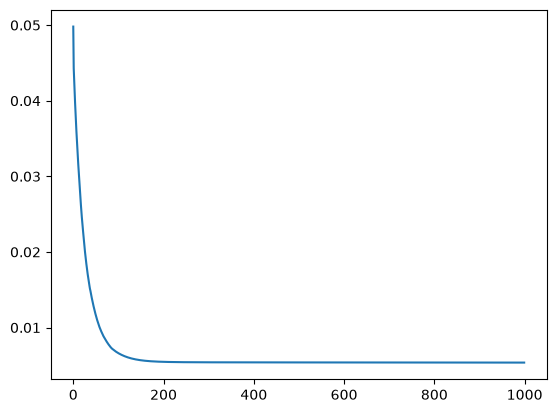

In [14]:
plt.plot(loss_points)

# we can limit the y-axis to see the learning better
# plt.ylim(-1, 3)
plt.show()

In [15]:
print("ORIGINAL WEIGHTS AND BIASES")
print(f"w1: {original_w1}")
print(f"w2: {original_w2}")
print(f"w3: {original_w3}")
print(f"w4: {original_w4}")
print(f"w5: {original_w5}")
print(f"w6: {original_w6}")
print(f"b1: {original_b1}")
print(f"b2: {original_b2}")
print(f"b3: {original_b3}")

print("\n\n##################################")

print("NEW WEIGHTS AND BIASES")
print(f"w1: {w1}")
print(f"w2: {w2}")
print(f"w3: {w3}")
print(f"w4: {w4}")
print(f"w5: {w5}")
print(f"w6: {w6}")
print(f"b1: {bias1}")
print(f"b2: {bias2}")
print(f"b3: {bias3}")


ORIGINAL WEIGHTS AND BIASES
w1: 1.5
w2: 0.5
w3: -2
w4: -0.5
w5: 1.5
w6: 1.2
b1: 0.5
b2: -0.35
b3: 0.5


##################################
NEW WEIGHTS AND BIASES
w1: 3.1835832919489833
w2: 0.5
w3: 0.4638089945843581
w4: -0.5
w5: 1.7898857814429903
w6: 1.2
b1: -0.256371923918616
b2: -0.35
b3: 0.2669907901013395


In [16]:
# prediction function, JUST DO THE FORWARD PASS
# (forward pass again, BUT ONLY THAT!)
def predict(x1, x2):
    input1 = x1
    input2 = x2

    # NODE 1 OUTPUT
    node_1_output = input1 * w1 + input2 * w3 + bias1
    node_1_output = activation_ReLu(node_1_output)

    # NODE 2 OUTPUT
    node_2_output = input1 * w2 + input2 * w4 + bias2
    node_2_output = activation_ReLu(node_2_output)

    # NODE 3 OUTPUT
    # we can just use Node 1 and 2 outputs, since they already
    # contain the previous weights in their result
    node_3_output = node_1_output * w5 + node_2_output * w6 + bias3
    node_3_output = activation_ReLu(node_3_output)
    return node_3_output

The model no longer gets stuck on the bias3 value.

In [25]:
# let's take one example row from the data
data[25]

array([0.11538462, 0.23076923, 0.65384615])

In [26]:
# convert the y-value (third value above) into an actual
# value by reverting the scaling
df['y'].max() * 0.65384615

np.float64(16.9999999)

In [ ]:
# try predicting with the data[25] values
result = predict(0.11538462, 0.23076923)
result

np.float64(0.6571813602703432)

In [28]:
# after reverting back to original format
# we can see that the result is quite close
df['y'].max() * 0.6571813602703432

np.float64(17.086715367028923)

In [18]:
data

array([[0.03846154, 0.19230769, 0.30769231],
       [0.        , 0.15384615, 0.30769231],
       [0.15384615, 0.23076923, 1.        ],
       [0.15384615, 0.19230769, 0.92307692],
       [0.        , 0.15384615, 0.15384615],
       [0.15384615, 0.15384615, 0.76923077],
       [0.03846154, 0.11538462, 0.26923077],
       [0.        , 0.11538462, 0.15384615],
       [0.07692308, 0.15384615, 0.46153846],
       [0.15384615, 0.15384615, 0.80769231],
       [0.        , 0.15384615, 0.15384615],
       [0.11538462, 0.11538462, 0.5       ],
       [0.03846154, 0.11538462, 0.19230769],
       [0.11538462, 0.19230769, 0.65384615],
       [0.        , 0.23076923, 0.34615385],
       [0.03846154, 0.19230769, 0.23076923],
       [0.07692308, 0.19230769, 0.34615385],
       [0.11538462, 0.23076923, 0.73076923],
       [0.11538462, 0.19230769, 0.53846154],
       [0.07692308, 0.11538462, 0.42307692],
       [0.        , 0.11538462, 0.15384615],
       [0.07692308, 0.23076923, 0.38461538],
       [0.

### TODO DURING THE NEXT LECTURE

In [ ]:
# ideas to try for the next version:

# MOST IMPORTANT! SCALE ALL THE VALUES!! (MinMaxScaling is enough)

# with real data, let's also modify the scaling: separate scaling for X and y

# remember also to check how to read prediction outputs after scaling

# FINALLY => use a real dataset => medical insurance dataset (read with pandas)